# Lab 03, Part B: Images to Numbers

**Course:** Introduction to Artificial Intelligence (AI-101L)

**How to run (one go):** click **Runtime -> Run all**. That is all.

By default (`MODE = "auto"`) the notebook downloads **10 car and 10 motorbike photos** from Wikimedia Commons (free licence). The sources are saved in `dataset_sources.csv`.
To use your own photos instead, set `MODE = "upload"` in the first code cell and upload a `data.zip` with two folders of images.
If the download fails, the notebook falls back to **synthetic (fake) images** so it still runs, but then you must re-run for the final submission.

In [1]:
!pip install -q Pillow numpy pandas matplotlib

import os, glob, zipfile, shutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# --- write image_utils.py (a deliverable) ---
open("image_utils.py", "w").write('''"""image_utils.py -- Lab 03: turn an image file into a fixed-length feature vector."""
import numpy as np
from PIL import Image


def image_to_features(path, size=(64, 64)):
    """Load, resize, grayscale and flatten an image into a 1-D feature vector.

    Parameters
    ----------
    path : str
        Path to an image file.
    size : tuple[int, int]
        Target (width, height). Every image is forced to this size so that
        every returned vector has the SAME length, which is what a model
        with a fixed number of input features requires.

    Returns
    -------
    numpy.ndarray of shape (size[0] * size[1],), dtype uint8
    """
    img = Image.open(path).convert("RGB")   # 1. same number of channels for every file
    img = img.resize(size)                  # 2. same width and height for every file
    img = img.convert("L")                  # 3. three channels -> one (grayscale)
    return np.array(img).flatten()          # 4. 2-D grid -> 1-D vector
''')
from image_utils import image_to_features
print("image_utils.py written. image_to_features is ready.")

image_utils.py written. image_to_features is ready.


In [2]:
# --- STEP 1: get the images ---------------------------------------------
# MODE = "auto"   -> download 10 car + 10 motorbike photos from Wikimedia Commons (free licence)
# MODE = "upload" -> upload your own data.zip (two folders of images)
MODE = "auto"

import requests, re, time, csv
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
USING_SYNTHETIC = False
UA = {"User-Agent": "AI101L-Lab03/1.0 (university lab exercise; educational use)"}
WIKI_API = "https://commons.wikimedia.org/w/api.php"
BAD = re.compile(r"diagram|logo|map|drawing|engine|interior|dashboard|wheel|sketch|icon|toy|lego|poster|advert|cutaway|museum|park|parking|garage|building|plate|badge", re.I)

def find_class_dirs(root):
    dirs = []
    for d, _, files in os.walk(root):
        if "__MACOSX" in d or "/." in d:
            continue
        if any(f.lower().endswith(IMG_EXT) and not f.startswith(".") for f in files):
            dirs.append(d)
    return sorted(dirs)

def wiki_candidates(queries, want, must, must_not=r'car park|parking|garage|accident|wreck|museum|model car|\btoys?\b|interior|engine|building|bicycle'):
    found, seen = [], set()
    for q in queries:
        params = {"action": "query", "format": "json", "generator": "search",
                  "gsrsearch": f"{q} filetype:bitmap", "gsrnamespace": 6, "gsrlimit": 50,
                  "prop": "imageinfo", "iiprop": "url|mime|size|extmetadata", "iiurlwidth": 400}
        r = requests.get(WIKI_API, params=params, headers=UA, timeout=20)
        r.raise_for_status()
        pages = r.json().get("query", {}).get("pages", {})
        for p in sorted(pages.values(), key=lambda p: p.get("index", 0)):
            info = (p.get("imageinfo") or [{}])[0]
            title = p.get("title", "")
            if info.get("mime") != "image/jpeg" or BAD.search(title):
                continue
            if info.get("width", 0) < 600 or info.get("height", 0) < 400:
                continue
            url = info.get("thumburl")
            if not url or url in seen:
                continue
            cats = info.get("extmetadata", {}).get("Categories", {}).get("value", "").lower()
            if not re.search(must, cats) or re.search(must_not, cats):
                continue   # the file must be in a category that really is a car / motorbike
            seen.add(url)
            lic = info.get("extmetadata", {}).get("LicenseShortName", {}).get("value", "")
            found.append({"title": title, "url": url, "page": info.get("descriptionurl", ""), "license": lic})
        time.sleep(0.5)
        if len(found) >= want * 2:
            break
    return found

def auto_download(class_queries, per_class=10):  # class_queries: {class: (must_regex, [search terms])}
    rows = []
    for cls, (must, queries) in class_queries.items():
        os.makedirs(f"data/{cls}", exist_ok=True)
        got = 0
        for cand in wiki_candidates(queries, per_class, must):
            if got >= per_class:
                break
            try:
                res = requests.get(cand["url"], headers=UA, timeout=20)
                res.raise_for_status()
                im = Image.open(io.BytesIO(res.content)).convert("RGB")
                got += 1
                im.save(f"data/{cls}/{cls}_{got:02d}.jpg")
                rows.append([cls, f"{cls}_{got:02d}.jpg", cand["title"], cand["license"], cand["page"]])
            except Exception as e:
                print(f"  [skip] {cand['title']} -> {str(e)[:80]}")
            time.sleep(0.5)
        print(f"{cls}: downloaded {got} images")
        if got < per_class:
            raise RuntimeError(f"only {got} usable images found for {cls}")
    with open("dataset_sources.csv", "w", newline="") as f:
        csv.writer(f).writerows([["class", "file", "wikimedia_title", "license", "source_page"]] + rows)

import io
shutil.rmtree("data", ignore_errors=True)
os.makedirs("data", exist_ok=True)
CLASS_PATHS = []

if MODE == "auto":
    try:
        auto_download({
            "car": (r"\bcars\b|automobile|sedan|hatchback|saloon|coupe|suv|passenger car",
                    ["hatchback car", "sedan car", "Toyota Corolla", "Volkswagen Golf", "Honda Civic", "Ford Focus", "Mazda car"]),
            "bike": (r"motorcycle|motorbike|scooter",
                     ["motorcycle", "motorbike", "Honda motorcycle", "Yamaha motorcycle", "Suzuki motorcycle"]),
        })
        CLASS_PATHS = ["data/bike", "data/car"]
    except Exception as e:
        print("Auto download failed:", e)
        shutil.rmtree("data", ignore_errors=True); os.makedirs("data", exist_ok=True)
else:
    try:
        from google.colab import files
        uploaded = files.upload()          # <- choose data.zip here
    except Exception as e:
        uploaded = {}
        print("Upload not available:", e)
    for name in uploaded:
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(name) as z:
                z.extractall("data")
    found_dirs = find_class_dirs("data")
    if uploaded and len(found_dirs) < 2:
        print("Your zip must contain TWO folders of images (one per class). Found:", found_dirs)
    CLASS_PATHS = found_dirs[:2]

if len(CLASS_PATHS) < 2:
    # ---- fallback: synthetic images so the notebook can still run ----
    USING_SYNTHETIC = True
    rng = np.random.default_rng(0)
    for cls, make in (("class_a", lambda h, w: np.tile(np.linspace(120, 255, w), (h, 1))),
                      ("class_b", lambda h, w: rng.integers(0, 90, size=(h, w)))):
        os.makedirs(f"data/{cls}", exist_ok=True)
        for i in range(10):
            h, w = int(rng.integers(80, 300)), int(rng.integers(80, 300))
            g = make(h, w).astype(np.uint8)
            rgb = np.stack([g, g // 2 + 40, 255 - g // 2], axis=-1).astype(np.uint8)
            Image.fromarray(rgb, "RGB").save(f"data/{cls}/img{i+1}.png")
    CLASS_PATHS = ["data/class_a", "data/class_b"]
    print("WARNING: no real images -> using SYNTHETIC images. Re-run with real images for submission!")

CLASS_NAMES = [os.path.basename(p) for p in CLASS_PATHS]
for label, p in enumerate(CLASS_PATHS):
    n = len([f for f in os.listdir(p) if f.lower().endswith(IMG_EXT)])
    print(f"Class {label}: {CLASS_NAMES[label]:<15} {n} images   ({p})")

car: downloaded 10 images
bike: downloaded 10 images
Class 0: bike            10 images   (data/bike)
Class 1: car             10 images   (data/car)


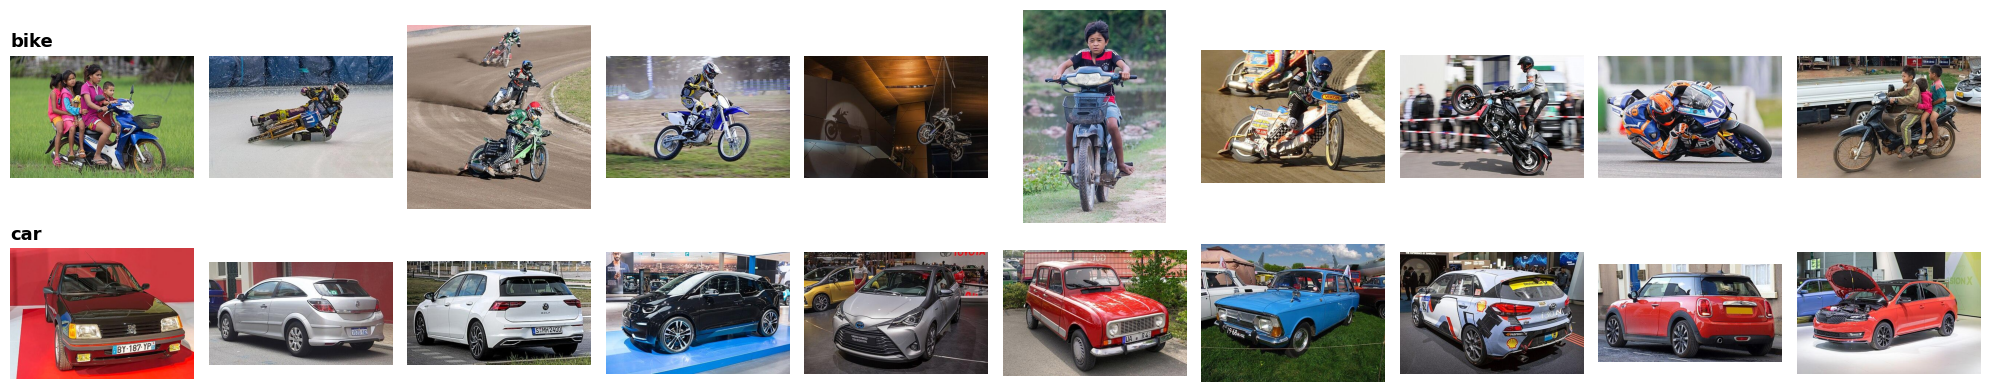

If any picture is in the wrong folder, delete it or change MODE to 'upload' and use your own photos.


In [3]:
# Look at the dataset! Check that the car folder really has cars and the bike folder bikes.
cols = 10
fig, axes = plt.subplots(len(CLASS_PATHS), cols, figsize=(20, 4.4))
for r, folder in enumerate(CLASS_PATHS):
    imgs = sorted(glob.glob(os.path.join(folder, "*")))[:cols]
    for c in range(cols):
        ax = axes[r][c]; ax.axis("off")
        if c < len(imgs):
            ax.imshow(Image.open(imgs[c]).convert("RGB"))
            if c == 0: ax.set_title(CLASS_NAMES[r], loc="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig_dataset_grid.png", dpi=110, bbox_inches="tight")
plt.show()
print("If any picture is in the wrong folder, delete it or change MODE to 'upload' and use your own photos.")

## Task 3.2: Converting and flattening image pixels

In [4]:
# Use the first image of class 0 as our sample photograph.
sample_path = sorted(glob.glob(os.path.join(CLASS_PATHS[0], "*")))[0]
original_image = Image.open(sample_path).convert("RGB")
original_image_array = np.array(original_image)

h, w, c = original_image_array.shape
print("Sample image:", sample_path)
print(f"Original Image Size (H, W, Channels): {original_image_array.shape}")
print(f"Total Features (Pixels) in RGB: {h * w * c}")

Sample image: data/bike/bike_01.jpg
Original Image Size (H, W, Channels): (333, 500, 3)
Total Features (Pixels) in RGB: 499500


In [5]:
# Step 1: grayscale conversion ('L' = luminance)
grayscale_image = original_image.convert("L")
grayscale_array = np.array(grayscale_image)

print("--- Grayscale Conversion (Feature Reduction) ---")
print(f"Grayscale Image Size (H, W): {grayscale_array.shape}")
print(f"Total Features (Pixels) after Grayscale: {grayscale_array.size}")
print(f"Reduction factor: {(h * w * c) / grayscale_array.size:.0f}x fewer features")

--- Grayscale Conversion (Feature Reduction) ---
Grayscale Image Size (H, W): (333, 500)
Total Features (Pixels) after Grayscale: 166500
Reduction factor: 3x fewer features


In [6]:
# Step 2: flatten (2-D matrix -> 1-D vector)
flattened_features = grayscale_array.flatten()

print("--- Pixel Flattening (Vectorization) ---")
print(f"Flattened Feature Vector Shape: {flattened_features.shape}")
print("First 10 Features (Pixel Values):", flattened_features[:10])
print("Data Type of Final Features:", flattened_features.dtype)

--- Pixel Flattening (Vectorization) ---
Flattened Feature Vector Shape: (166500,)
First 10 Features (Pixel Values): [31 17 19 27 22 21 28 30 25 23]
Data Type of Final Features: uint8


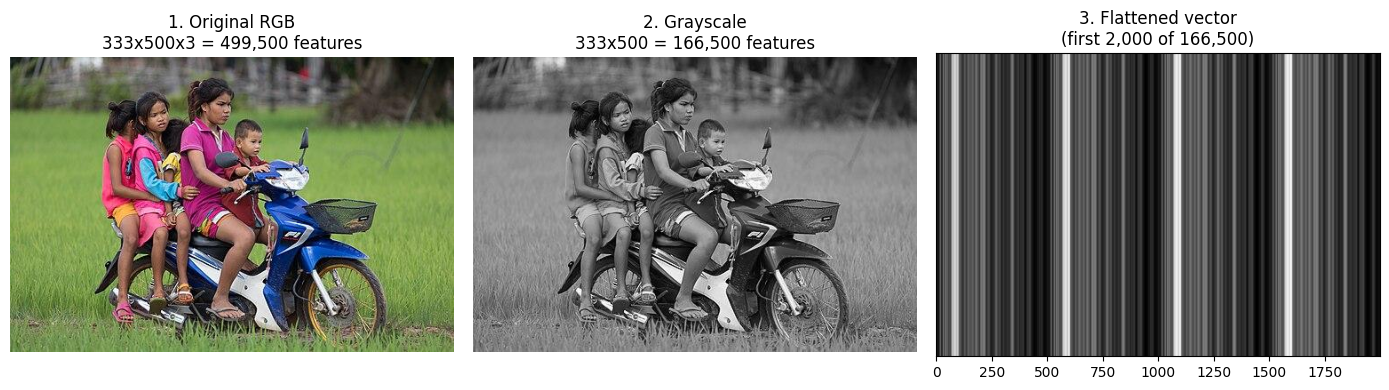

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(original_image)
axes[0].set_title(f"1. Original RGB\n{h}x{w}x{c} = {h*w*c:,} features"); axes[0].axis("off")
axes[1].imshow(grayscale_image, cmap="gray")
axes[1].set_title(f"2. Grayscale\n{h}x{w} = {h*w:,} features"); axes[1].axis("off")
axes[2].imshow(flattened_features[:2000].reshape(1, -1), cmap="gray", aspect="auto")
axes[2].set_title(f"3. Flattened vector\n(first 2,000 of {flattened_features.size:,})"); axes[2].set_yticks([])
plt.tight_layout()
plt.savefig("fig_pipeline.png", dpi=150, bbox_inches="tight")
plt.show()

## In-lab exercises (images)

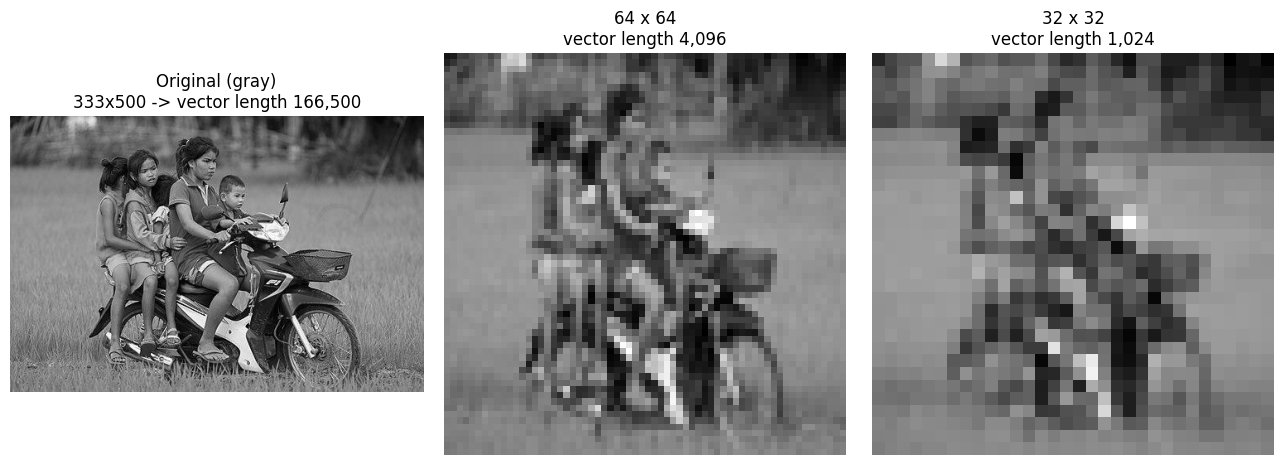

Flattened vector lengths:
  original (333x500) : 166,500
  64 x 64          : 4,096
  32 x 32          : 1,024


In [8]:
# --- Exercise 3: resize to 64x64 and 32x32, compare with the original ---
img64 = original_image.resize((64, 64)).convert("L")
img32 = original_image.resize((32, 32)).convert("L")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(grayscale_image, cmap="gray")
axes[0].set_title(f"Original (gray)\n{h}x{w} -> vector length {h*w:,}")
axes[1].imshow(img64, cmap="gray")
axes[1].set_title("64 x 64\nvector length 4,096")
axes[2].imshow(img32, cmap="gray")
axes[2].set_title("32 x 32\nvector length 1,024")
for a in axes: a.axis("off")
plt.tight_layout()
plt.savefig("fig_exercise3_resize.png", dpi=150, bbox_inches="tight")
plt.show()

print("Flattened vector lengths:")
print(f"  original ({h}x{w}) : {h*w:,}")
print(f"  64 x 64          : {np.array(img64).size:,}")
print(f"  32 x 32          : {np.array(img32).size:,}")

In [9]:
# --- Exercise 4: image_to_features gives the SAME length for different image sizes ---
paths = [p for cls in CLASS_PATHS for p in sorted(glob.glob(os.path.join(cls, "*")))]
test_paths = paths[:1] + paths[len(paths)//2:len(paths)//2 + 1] + paths[-1:]   # three different files

lengths = []
for p in test_paths:
    orig_size = Image.open(p).size            # (width, height)
    v = image_to_features(p, size=(64, 64))
    lengths.append(v.shape[0])
    print(f"{os.path.relpath(p, 'data'):<26} original {orig_size[0]}x{orig_size[1]}  ->  vector length {v.shape[0]}")

assert len(set(lengths)) == 1, "Vector lengths differ!"
print("\nAll three vectors have identical length -- a model can accept any of them.")

bike/bike_01.jpg           original 500x333  ->  vector length 4096
car/car_01.jpg             original 500x356  ->  vector length 4096
car/car_10.jpg             original 500x333  ->  vector length 4096

All three vectors have identical length -- a model can accept any of them.


## Home assignment: 20 images, 2 classes

In [10]:
SIZE = (64, 64)
X_list, y_list = [], []
for label, folder in enumerate(CLASS_PATHS):
    for p in sorted(glob.glob(os.path.join(folder, "*"))):
        if not p.lower().endswith(IMG_EXT):
            continue
        try:
            X_list.append(image_to_features(p, size=SIZE))
            y_list.append(label)
        except Exception as e:
            print(f"[SKIP] {p} -> {e}")

X = np.vstack(X_list)
y = np.array(y_list)
np.savez("dataset.npz", X=X, y=y)

print(f"X shape: {X.shape}   y shape: {y.shape}")
print(f"Samples: {X.shape[0]}   Features per sample: {X.shape[1]}")
print(f"Samples per feature: {X.shape[0] / X.shape[1]:.4f}")
print("Class counts:", {CLASS_NAMES[k]: int((y == k).sum()) for k in range(len(CLASS_NAMES))})
print("Saved dataset.npz")
if USING_SYNTHETIC:
    print("\n*** WARNING: this dataset is SYNTHETIC. Re-run with your real images before submitting. ***")

X shape: (20, 4096)   y shape: (20,)
Samples: 20   Features per sample: 4096
Samples per feature: 0.0049
Class counts: {'bike': 10, 'car': 10}
Saved dataset.npz


In [11]:
# --- Copy-friendly summary for the report, then download the deliverables ---
print("=== NUMBERS FOR report.md ===")
print(f"Sample image size (H x W x C): {h} x {w} x {c}  -> RGB features {h*w*c:,}")
print(f"Grayscale features: {h*w:,}  (flattened length = H x W = {h*w:,})")
print(f"Dataset X: {X.shape}, y: {y.shape}, classes: {CLASS_NAMES}")
print(f"Samples per feature: {X.shape[0] / X.shape[1]:.4f}")

try:
    from google.colab import files
    for f in ["dataset.npz", "image_utils.py", "fig_pipeline.png", "fig_exercise3_resize.png", "fig_dataset_grid.png", "dataset_sources.csv"]:
        files.download(f)
except Exception as e:
    print("Download skipped:", e)

=== NUMBERS FOR report.md ===
Sample image size (H x W x C): 333 x 500 x 3  -> RGB features 499,500
Grayscale features: 166,500  (flattened length = H x W = 166,500)
Dataset X: (20, 4096), y: (20,), classes: ['bike', 'car']
Samples per feature: 0.0049


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Discussion questions (Part B): my answers

**1. How does grayscale conversion act as feature engineering?**
A colour image has three channels (red, green, blue) per pixel. Grayscale replaces them with **one brightness value** per pixel, so the number of features becomes **three times smaller**. It keeps shapes, edges and brightness, and throws away colour. This gives a simpler input, less memory, faster training and less risk of overfitting. It is a good trade when colour does not matter (reading digits) and a bad one when colour is the clue (ripe vs unripe fruit).

**2. If the image is H x W pixels, how long is the flattened vector after grayscale?**
The length is **H x W** (one number per pixel). For example, a 64 x 64 image gives 4,096 numbers.

**3. Why is flattening needed before Logistic Regression or an SVM?**
These models expect **each sample to be one row of numbers** (a 1-D vector), so the data forms a 2-D table `X` of shape (number of samples, number of features). A 2-D pixel grid does not fit that shape. Flattening reads the grid row by row and gives the vector. The cost: the model no longer knows which pixels were neighbours.

**4. Why resize all images to the same size (for example 64 x 64)?**
Photos have different sizes, so their flattened vectors would have **different lengths**. A model has a fixed number of input features and `np.vstack` cannot stack vectors of different lengths into one matrix. Resizing guarantees the same length for every image. A smaller size also means fewer features, less memory and faster training. The cost is lost fine detail and a possibly stretched shape.

**Exercise 3 (resize):** at 64 x 64 the vector has 4,096 numbers, and at 32 x 32 it has 1,024. As the size drops, fine details such as texture, thin lines and small objects disappear first. At 32 x 32 only the rough shapes and brightness blobs remain.

**Exercise 4:** `image_to_features(path, size=(64, 64))` returns a vector of length 4,096 for every image, whatever its original size (see the output above).

## Paragraph: is 20 samples in 4,096 dimensions a sound basis for learning?

No. Our matrix `X` has shape (20, 4096): there are about **200 times more features than samples** (0.005 samples per feature). This is the "curse of dimensionality". With so many dimensions and so few examples, a model can easily find a rule that separates the 20 training images perfectly by chance (**overfitting**), and it will then fail on new images. Distances between points also become less meaningful in very high dimensions. Neighbouring pixels are highly correlated, so many of the 4,096 features carry almost the same information. Better options are: collect far more images (hundreds per class), use a smaller size (such as 16 x 16 = 256 features), reduce dimensions with PCA (Lab 6), or use a CNN (Lab 8), which uses the 2-D structure of the image and shares weights, so it needs far fewer parameters.